# Smarter Spam Detection: Catching Spam Without Blocking Legitimate Messages

**Course:** ARTI 405 — Natural Language Processing (Section 7MA1)  
**Instructor:** Dr. Ahmed Talal  
**Group:** Group 1  
**Team Members:**
- Abdulrahman Alshaikh (2240004223)
- Abdulrahman Fahad AlHumam (2240002411)
- Ibrahim Khaled Alkhamis (2240004075)

**Project Option:** Option 1 — Spam Detection  
**Research Question:** Can a text classifier keep spam detection high while reducing how often legitimate, suspicious-looking messages (such as OTP codes, bank alerts, delivery updates, and appointment reminders) are wrongly flagged as spam?

This notebook implements our complete experimental pipeline comparing two traditional TF-IDF baselines (**Multinomial Naive Bayes** and **Logistic Regression**) against a fine-tuned pretrained language model (**BERT**, `bert-base-uncased`) using identical leak-free data splits, development-set threshold tuning, hard-case false-alarm evaluation, error analysis, and an interactive prediction demo.


## Setup

**Execution Environment:** Google Colab (T4 GPU recommended for fast BERT fine-tuning; automatically falls back to CPU if no GPU is available).

If you are running this notebook in a fresh Google Colab session:
1. Enable a GPU via **Runtime → Change runtime type → T4 GPU**.
2. Upload the `data/` folder (containing `hard_cases.csv` and `student_examples.csv`) into the Colab working directory. The UCI SMS Spam Collection dataset is downloaded automatically if not already present in `data/`.
3. Run all cells in order (**Runtime → Restart session and run all**).

The cell below installs/verifies required packages, prints library versions for reproducibility, sets fixed random seeds, and creates relative output directories.


In [1]:
# Install dependencies if running on a fresh environment (uncomment if needed)
# !pip -q install -r requirements.txt

import os
import re
import json
import math
import random
import urllib.request
import zipfile
import platform
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import sklearn
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import transformers
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

# Reproducibility settings
SEED = 405
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

# Relative paths for data and saved results
DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

# Device configuration
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Experiment configuration
BERT_MODEL_NAME = "bert-base-uncased"
MAX_SEQ_LEN = 128
BERT_EPOCHS = 3
BERT_BATCH_SIZE = 16
BERT_LR = 2e-5
RECALL_TARGET = 0.90
THRESHOLD_GRID = [round(0.50 + 0.05 * i, 2) for i in range(10)]  # 0.50 to 0.95

print(f"Python:        {platform.python_version()}")
print(f"PyTorch:       {torch.__version__} | Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU:           {torch.cuda.get_device_name(0)}")
print(f"Transformers:  {transformers.__version__}")
print(f"Scikit-learn:  {sklearn.__version__}")
print(f"Pandas:        {pd.__version__} | NumPy: {np.__version__}")
print(f"Random Seed:   {SEED}")


Python:        3.13.16
PyTorch:       2.14.1+cu130 | Device: cuda
GPU:           Tesla T4
Transformers:  5.22.1
Scikit-learn:  1.6.1
Pandas:        2.2.3 | NumPy: 2.4.6
Random Seed:   405


## Data

### 1. UCI SMS Spam Collection Loading, Deduplication, and Leak-Free Splitting
We use the **UCI SMS Spam Collection** dataset (Almeida & Hidalgo, 2011), containing 5,574 English SMS messages labelled as `ham` (legitimate) or `spam`.

To ensure fair testing and avoid data leakage across splits:
- **Exact Duplicate Removal:** Messages are lowercased and normalized for extra whitespace; exact duplicates are removed, and we assert that no normalized message carries conflicting labels.
- **Template Grouping:** Near-duplicate templates that differ only by URLs, numeric codes/phone numbers, or punctuation are mapped to a shared group key so related variants remain in the same split.
- **Three-Way Split (Train / Dev / Test):** Using `StratifiedGroupKFold(n_splits=5)`, we assign 3 folds (~60%) to `train`, 1 fold (~20%) to `dev`, and 1 fold (~20%) to `test`. Model parameters are learned only on `train`, decision thresholds and model selection are decided strictly on `dev`, and `test` is reserved solely for final evaluation.

### 2. Hard-Case Legitimate Test Set and Individual Examples
- **`data/hard_cases.csv`**: 100 original legitimate (`ham`) messages resembling spam across four realistic categories (25 OTP codes, 25 bank alerts, 25 delivery notices, 25 appointment reminders). Never used for training or threshold tuning.
- **`data/student_examples.csv`**: 6 original labelled examples (2 per team member), evaluated separately from the benchmark test metrics.


In [3]:
def ensure_uci_dataset(data_dir: Path) -> Path:
    """Locate SMSSpamCollection locally or download it from the UCI repository."""
    target_file = data_dir / "SMSSpamCollection"
    if target_file.exists():
        return target_file

    # Check if uploaded directly to the root directory
    root_file = Path("SMSSpamCollection")
    if root_file.exists():
        target_file.write_bytes(root_file.read_bytes())
        return target_file

    # Download official UCI archive
    zip_path = data_dir / "sms_spam_collection.zip"
    uci_url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
    print(f"Downloading UCI SMS Spam Collection from {uci_url} ...")
    urllib.request.urlretrieve(uci_url, zip_path)

    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(data_dir)

    if not target_file.exists():
        raise FileNotFoundError("SMSSpamCollection was not found after extracting the UCI archive.")
    print("Dataset downloaded and extracted to data/SMSSpamCollection.")
    return target_file


def resolve_csv_path(filename: str, data_dir: Path) -> Path:
    """Locate a project CSV file in data/ or the notebook root directory."""
    in_data = data_dir / filename
    if in_data.exists():
        return in_data
    in_root = Path(filename)
    if in_root.exists():
        return in_root
    raise FileNotFoundError(
        f"Could not find '{filename}'. Please place it inside the 'data/' folder."
    )


# Load raw UCI dataset
uci_path = ensure_uci_dataset(DATA_DIR)
records = [
    line.split("\t", 1)
    for line in uci_path.read_text(encoding="utf-8").splitlines()
    if line.strip()
]
raw_df = pd.DataFrame(records, columns=["label", "text"])

# Validate raw labels and non-empty text
assert set(raw_df["label"]) == {"ham", "spam"}, "Unexpected label values in UCI dataset."
assert raw_df["text"].str.strip().ne("").all(), "Found empty SMS rows in UCI dataset."

# Remove exact normalized duplicates and verify label consistency
raw_df["norm_key"] = (
    raw_df["text"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
)
assert raw_df.groupby("norm_key")["label"].nunique().max() == 1, "Conflicting labels detected."

clean_df = raw_df.drop_duplicates("norm_key").copy().reset_index(drop=True)
clean_df["y"] = clean_df["label"].map({"ham": 0, "spam": 1})

# Group near-duplicate templates (URLs, digits, and punctuation normalized)
def make_template_group(text: str) -> str:
    text = re.sub(r"https?://\S+|www\.\S+", " url ", text.lower())
    text = re.sub(r"\d+", " number ", text)
    return " ".join(re.sub(r"[^a-z ]", " ", text).split())

clean_df["group"] = clean_df["text"].map(make_template_group)

# Leak-free stratified group split: 3 folds train, 1 fold dev, 1 fold test
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
clean_df["split"] = "train"
for fold_idx, (_, val_idx) in enumerate(sgkf.split(clean_df["text"], clean_df["y"], clean_df["group"])):
    if fold_idx == 0:
        clean_df.loc[val_idx, "split"] = "test"
    elif fold_idx == 1:
        clean_df.loc[val_idx, "split"] = "dev"

# Verify zero template group overlap between splits
assert clean_df.groupby("group")["split"].nunique().max() == 1, "Group leakage detected across splits!"

splits = {name: clean_df[clean_df["split"] == name].reset_index(drop=True) for name in ["train", "dev", "test"]}
y_splits = {name: part["y"].to_numpy() for name, part in splits.items()}

split_table = pd.crosstab(clean_df["split"], clean_df["label"]).reindex(["train", "dev", "test"])
split_table["total"] = split_table["ham"] + split_table["spam"]
split_table["spam_pct"] = (split_table["spam"] / split_table["total"] * 100).round(2)
split_table.to_csv(RESULTS_DIR / "split_counts.csv")

print(f"Raw messages:        {len(raw_df)} (ham={(raw_df['label']=='ham').sum()}, spam={(raw_df['label']=='spam').sum()})")
print(f"Duplicates removed:  {len(raw_df) - len(clean_df)}")
print(f"Clean messages:      {len(clean_df)} (ham={(clean_df['label']=='ham').sum()}, spam={(clean_df['label']=='spam').sum()})")
print(f"Unique groups:       {clean_df['group'].nunique()}")
display(split_table)

# Load hard-case legitimate test set (100 ham messages)
hard_df = pd.read_csv(resolve_csv_path("hard_cases.csv", DATA_DIR), keep_default_na=False)
assert len(hard_df) == 100, f"Expected 100 hard cases, got {len(hard_df)}."
assert hard_df["label"].eq("ham").all(), "All hard-case rows must be labelled 'ham'."
assert hard_df["text"].nunique() == 100, "Duplicate texts found in hard_cases.csv."
print(f"\nLoaded hard-case test set: {len(hard_df)} legitimate messages across {hard_df['category'].nunique()} categories:")
display(hard_df["category"].value_counts().rename("count").to_frame())

# Load individual student examples (6 original messages, separate from test set)
student_df = pd.read_csv(resolve_csv_path("student_examples.csv", DATA_DIR), keep_default_na=False)
print(f"Loaded individual team examples: {len(student_df)} messages ({student_df['student_name'].nunique()} members).")


Raw messages:        5574 (ham=4827, spam=747)
Duplicates removed:  415
Clean messages:      5159 (ham=4517, spam=642)
Unique groups:       5096


label,ham,spam,total,spam_pct
split,,,,
train,2706,388,3094,12.54
dev,900,130,1030,12.62
test,911,124,1035,11.98



Loaded hard-case test set: 100 legitimate messages across 4 categories:


,count
category,
otp,25
bank_alert,25
delivery,25
appointment,25


Loaded individual team examples: 6 messages (3 members).


## Method 1: Traditional Lexical Classifiers (TF-IDF + Naive Bayes & Logistic Regression)

Following our proposal, the traditional NLP pipeline prepares text by:
1. Converting characters to lowercase.
2. Removing punctuation while keeping alphanumeric tokens (such as numeric codes and short numbers).
3. Filtering out standard English stop words (`scikit-learn` list).
4. Extracting **TF-IDF** unigram and bigram features (`ngram_range=(1, 2)`, `min_df=2`), fitted **strictly on the training split** so no vocabulary or document-frequency statistics leak from `dev` or `test`.

We train two classical models on this representation:
- **Multinomial Naive Bayes (`alpha=0.1`)**: fast probabilistic baseline relying on conditional word independence.
- **Logistic Regression (`C=1.0`, `class_weight='balanced'`)**: linear discriminative classifier that handles the ~12.5% spam class imbalance and allows direct inspection of word-level spam weights.


In [4]:
def clean_text_lexical(text: str) -> str:
    """Lowercase text, strip punctuation, and remove English stop words."""
    tokens = re.sub(r"[^a-z0-9\s]", " ", text.lower()).split()
    return " ".join(tok for tok in tokens if tok not in ENGLISH_STOP_WORDS)


# Fit TF-IDF vectorizer on training messages only
tfidf_vectorizer = TfidfVectorizer(
    preprocessor=clean_text_lexical,
    lowercase=False,
    ngram_range=(1, 2),
    min_df=2,
)

X_tfidf = {
    "train": tfidf_vectorizer.fit_transform(splits["train"]["text"]),
    "dev": tfidf_vectorizer.transform(splits["dev"]["text"]),
    "test": tfidf_vectorizer.transform(splits["test"]["text"]),
}

print("TF-IDF vocabulary size:", len(tfidf_vectorizer.get_feature_names_out()))
print("TF-IDF train matrix shape:", X_tfidf["train"].shape)
print("Sample cleaning output:", clean_text_lexical("URGENT: Your FREE appointment is confirmed at 10:30!"))

# Train traditional models
traditional_models = {
    "TF-IDF NB": MultinomialNB(alpha=0.1),
    "TF-IDF LR": LogisticRegression(C=1.0, class_weight="balanced", max_iter=1000, random_state=SEED),
}

dev_probs = {}
test_probs = {}

for name, clf in traditional_models.items():
    clf.fit(X_tfidf["train"], y_splits["train"])
    dev_probs[name] = clf.predict_proba(X_tfidf["dev"])[:, 1]
    print(f"Trained {name} on {X_tfidf['train'].shape[0]} training messages.")


TF-IDF vocabulary size: 4219
TF-IDF train matrix shape: (3094, 4219)
Sample cleaning output: urgent free appointment confirmed 10 30
Trained TF-IDF NB on 3094 training messages.
Trained TF-IDF LR on 3094 training messages.


## Method 2: Pretrained Language Model (Fine-Tuned BERT)

To address the limitation of bag-of-words features—which flag trigger words like `"verify"`, `"free"`, or `"account"` regardless of context—we fine-tune **`bert-base-uncased`** (`AutoModelForSequenceClassification` with 2 output classes) using the Hugging Face `transformers` library.

Unlike the TF-IDF pipeline, BERT receives the **original, unmodified SMS text** so its WordPiece tokenizer and self-attention layers can utilize punctuation, phrasing, and surrounding sentence context. Key training choices:
- **Max sequence length:** 128 tokens (covers virtually all SMS lengths cleanly).
- **Optimizer & Schedule:** `AdamW` with learning rate `2e-5`, weight decay `0.01`, linear warmup (10% of steps), and gradient clipping (`max_norm=1.0`).
- **Imbalance Handling:** Inverse class-frequency weights inside `CrossEntropyLoss` so spam and ham receive balanced emphasis during fine-tuning.
- **Checkpoint Selection:** Evaluated on the `dev` split after each epoch; the weights achieving the highest development Macro F1 are retained for threshold tuning and final testing.


In [5]:
class SMSDataset(Dataset):
    """PyTorch Dataset wrapping raw SMS texts and optional binary labels for BERT."""
    def __init__(self, texts, labels=None, tokenizer=None, max_len=MAX_SEQ_LEN):
        self.texts = list(texts)
        self.labels = None if labels is None else list(labels)
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoded = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt",
        )
        item = {
            "input_ids": encoded["input_ids"].squeeze(0),
            "attention_mask": encoded["attention_mask"].squeeze(0),
        }
        if self.labels is not None:
            item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item


@torch.no_grad()
def bert_predict_proba(model, texts, tokenizer, batch_size=32):
    """Return positive-class (spam) probabilities from the fine-tuned BERT model."""
    model.eval()
    ds = SMSDataset(texts, labels=None, tokenizer=tokenizer, max_len=MAX_SEQ_LEN)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False)
    probs = []
    for batch in loader:
        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        spam_p = torch.softmax(outputs.logits, dim=-1)[:, 1]
        probs.extend(spam_p.cpu().numpy().tolist())
    return np.array(probs, dtype=np.float64)


# Load pretrained tokenizer and sequence classification head
set_seed(SEED)
bert_tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_NAME)
bert_model = AutoModelForSequenceClassification.from_pretrained(
    BERT_MODEL_NAME,
    num_labels=2,
).to(DEVICE)

train_ds = SMSDataset(splits["train"]["text"], y_splits["train"], tokenizer=bert_tokenizer)
train_loader = DataLoader(train_ds, batch_size=BERT_BATCH_SIZE, shuffle=True)

# Balanced class weights computed strictly from training labels
n_ham = int((y_splits["train"] == 0).sum())
n_spam = int((y_splits["train"] == 1).sum())
class_weights = torch.tensor(
    [len(y_splits["train"]) / (2.0 * n_ham), len(y_splits["train"]) / (2.0 * n_spam)],
    dtype=torch.float32,
    device=DEVICE,
)
criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.AdamW(bert_model.parameters(), lr=BERT_LR, weight_decay=0.01)
total_steps = len(train_loader) * BERT_EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps,
)

best_dev_f1 = -1.0
best_state_dict = None
bert_history = []

print(f"Fine-tuning {BERT_MODEL_NAME} for {BERT_EPOCHS} epochs on {DEVICE}...")
for epoch in range(1, BERT_EPOCHS + 1):
    bert_model.train()
    running_loss = 0.0

    for batch in train_loader:
        optimizer.zero_grad()
        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)

        outputs = bert_model(input_ids=input_ids, attention_mask=attention_mask)
        loss = criterion(outputs.logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(bert_model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        running_loss += loss.item()

    avg_loss = running_loss / len(train_loader)
    ep_dev_probs = bert_predict_proba(bert_model, splits["dev"]["text"], bert_tokenizer)
    ep_dev_preds = (ep_dev_probs >= 0.50).astype(int)
    ep_acc = accuracy_score(y_splits["dev"], ep_dev_preds)
    ep_macro_f1 = f1_score(y_splits["dev"], ep_dev_preds, average="macro", zero_division=0)
    ep_recall = recall_score(y_splits["dev"], ep_dev_preds, zero_division=0)

    bert_history.append({
        "epoch": epoch,
        "train_loss": round(avg_loss, 4),
        "dev_accuracy": round(ep_acc, 4),
        "dev_macro_f1": round(ep_macro_f1, 4),
        "dev_spam_recall": round(ep_recall, 4),
    })
    print(
        f"Epoch {epoch}/{BERT_EPOCHS} | Train Loss: {avg_loss:.4f} | "
        f"Dev Acc: {ep_acc:.4f} | Dev Macro F1: {ep_macro_f1:.4f} | Dev Spam Recall: {ep_recall:.4f}"
    )

    if ep_macro_f1 > best_dev_f1:
        best_dev_f1 = ep_macro_f1
        best_state_dict = {k: v.cpu().clone() for k, v in bert_model.state_dict().items()}

# Restore best checkpoint based on development Macro F1
bert_model.load_state_dict({k: v.to(DEVICE) for k, v in best_state_dict.items()})
bert_model.eval()

dev_probs["BERT"] = bert_predict_proba(bert_model, splits["dev"]["text"], bert_tokenizer)
pd.DataFrame(bert_history).to_csv(RESULTS_DIR / "bert_training_history.csv", index=False)
print(f"Restored best BERT checkpoint (Dev Macro F1 @ 0.50 = {best_dev_f1:.4f}).")


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Fine-tuning bert-base-uncased for 3 epochs on cuda...
Epoch 1/3 | Train Loss: 0.2341 | Dev Acc: 0.9913 | Dev Macro F1: 0.9803 | Dev Spam Recall: 0.9692
Epoch 2/3 | Train Loss: 0.0668 | Dev Acc: 0.9913 | Dev Macro F1: 0.9803 | Dev Spam Recall: 0.9692
Epoch 3/3 | Train Loss: 0.0314 | Dev Acc: 0.9922 | Dev Macro F1: 0.9825 | Dev Spam Recall: 0.9769
Restored best BERT checkpoint (Dev Macro F1 @ 0.50 = 0.9825).


## Results

### 1. Decision Threshold Selection on the Development Split
To reduce false alarms on legitimate messages without losing spam protection, we evaluate candidate thresholds from **0.50 to 0.95** (step `0.05`) on the **development split** for every model.

**Selection Rule (locked before viewing test results):**
- Keep only thresholds achieving at least **90% development spam recall**.
- Among eligible thresholds, select the one with the **lowest Ham False Positive Rate (FPR)** (breaking ties by higher spam recall, then lower threshold).
- If no threshold meets the 90% recall target, fall back to the default `0.50` threshold and record `target_met = False`.
- Select the model for the `Try it` demo by highest development Macro F1 at its chosen threshold.


In [6]:
def compute_metrics(y_true, scores, threshold):
    """Compute classification metrics with spam (1) as the positive class."""
    y_pred = (np.asarray(scores) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    ham_fpr = fp / (tn + fp) if (tn + fp) > 0 else 0.0
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "spam_precision": precision_score(y_true, y_pred, zero_division=0),
        "spam_recall": recall_score(y_true, y_pred, zero_division=0),
        "spam_f1": f1_score(y_true, y_pred, zero_division=0),
        "ham_fpr": ham_fpr,
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }


MODEL_ORDER = ["TF-IDF NB", "TF-IDF LR", "BERT"]
dev_grid_rows = []
dev_selected_rows = []
selected_thresholds = {}

for name in MODEL_ORDER:
    scores = dev_probs[name]
    rows = [{"model": name, "threshold": t, **compute_metrics(y_splits["dev"], scores, t)} for t in THRESHOLD_GRID]
    dev_grid_rows.extend(rows)

    eligible = [r for r in rows if r["spam_recall"] >= RECALL_TARGET]
    if eligible:
        winner = min(eligible, key=lambda r: (r["ham_fpr"], -r["spam_recall"], r["threshold"]))
        target_met = True
    else:
        winner = rows[0]  # fallback to 0.50
        target_met = False

    selected_thresholds[name] = winner["threshold"]
    dev_selected_rows.append({**winner, "target_met": target_met})

dev_grid_df = pd.DataFrame(dev_grid_rows)
dev_choices_df = pd.DataFrame(dev_selected_rows)
dev_grid_df.to_csv(RESULTS_DIR / "dev_threshold_grid.csv", index=False)
dev_choices_df.to_csv(RESULTS_DIR / "dev_selected_thresholds.csv", index=False)

# Pick the best model for the interactive demo based on Dev Macro F1
SELECTED_DEMO_MODEL = dev_choices_df.sort_values(
    by=["macro_f1", "ham_fpr"], ascending=[False, True]
).iloc[0]["model"]

print("Development-Set Threshold Selection Summary:")
display(dev_choices_df[["model", "threshold", "accuracy", "macro_f1", "spam_recall", "ham_fpr", "fp", "fn", "target_met"]].round(4))
print(f"Selected model for Try it demo (based strictly on Dev Macro F1): {SELECTED_DEMO_MODEL} (threshold = {selected_thresholds[SELECTED_DEMO_MODEL]})")


Development-Set Threshold Selection Summary:


,model,threshold,accuracy,macro_f1,spam_recall,ham_fpr,fp,fn,target_met
0,TF-IDF NB,0.50,0.9777,0.9471,0.8615,0.0056,5,18,False
1,TF-IDF LR,0.50,0.9777,0.9489,0.9000,0.0111,10,13,True
2,BERT,0.95,0.9922,0.9824,0.9692,0.0044,4,4,True


Selected model for Try it demo (based strictly on Dev Macro F1): BERT (threshold = 0.95)


### 2. Final Evaluation on the Held-Out UCI Test Set
We now evaluate all three models on the exact same 1,035 unseen test messages (`ham` and `spam`) at both the default `0.50` threshold and their development-selected thresholds.


UCI Held-Out Test Set Results (Default vs. Development-Tuned Thresholds):


,model,mode,threshold,accuracy,macro_f1,spam_precision,spam_recall,spam_f1,ham_fpr,tn,fp,fn,tp
0,TF-IDF NB,Default,0.50,0.9836,0.9592,0.9820,0.8790,0.9277,0.0022,909,2,15,109
1,TF-IDF NB,Tuned,0.50,0.9836,0.9592,0.9820,0.8790,0.9277,0.0022,909,2,15,109
2,TF-IDF LR,Default,0.50,0.9836,0.9612,0.9280,0.9355,0.9317,0.0099,902,9,8,116
3,TF-IDF LR,Tuned,0.50,0.9836,0.9612,0.9280,0.9355,0.9317,0.0099,902,9,8,116
4,BERT,Default,0.50,0.9923,0.9817,0.9677,0.9677,0.9677,0.0044,907,4,4,120
5,BERT,Tuned,0.95,0.9913,0.9793,0.9675,0.9597,0.9636,0.0044,907,4,5,119


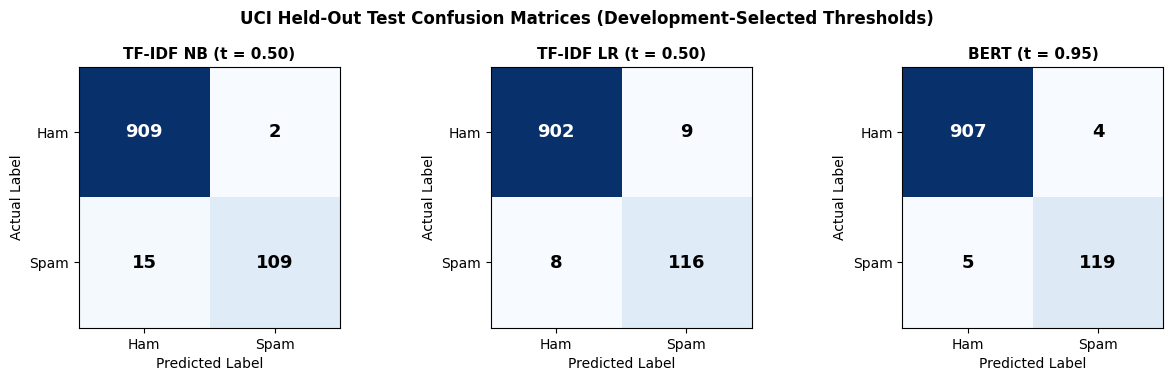

In [7]:
# Generate test-set probabilities once for all models
for name, clf in traditional_models.items():
    test_probs[name] = clf.predict_proba(X_tfidf["test"])[:, 1]
test_probs["BERT"] = bert_predict_proba(bert_model, splits["test"]["text"], bert_tokenizer)

# Evaluate default vs development-selected thresholds
test_rows = []
test_pred_df = splits["test"][["text", "label"]].copy()

for name in MODEL_ORDER:
    test_pred_df[f"{name}_prob"] = test_probs[name]
    for mode, thresh in [("Default", 0.50), ("Tuned", selected_thresholds[name])]:
        test_rows.append({
            "model": name,
            "mode": mode,
            "threshold": thresh,
            **compute_metrics(y_splits["test"], test_probs[name], thresh),
        })

test_metrics_df = pd.DataFrame(test_rows)
test_metrics_df.to_csv(RESULTS_DIR / "uci_test_metrics.csv", index=False)
test_pred_df.to_csv(RESULTS_DIR / "uci_test_predictions.csv", index=False)

print("UCI Held-Out Test Set Results (Default vs. Development-Tuned Thresholds):")
display(test_metrics_df.round(4))

# Plot side-by-side confusion matrices at development-selected thresholds
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.8))
for ax, name in zip(axes, MODEL_ORDER):
    thresh = selected_thresholds[name]
    preds = (test_probs[name] >= thresh).astype(int)
    cm = confusion_matrix(y_splits["test"], preds, labels=[0, 1])
    ax.imshow(cm, cmap="Blues")
    ax.set_title(f"{name} (t = {thresh:.2f})", fontsize=11, fontweight="bold")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Ham", "Spam"])
    ax.set_yticklabels(["Ham", "Spam"])
    for (i, j), val in np.ndenumerate(cm):
        ax.text(
            j, i, str(val),
            ha="center", va="center",
            color="white" if val > cm.max() / 2 else "black",
            fontsize=13, fontweight="bold"
        )

fig.suptitle("UCI Held-Out Test Confusion Matrices (Development-Selected Thresholds)", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "uci_confusion_matrices.png", dpi=200)
plt.show()


### 3. Evaluation on the Hard-Case Legitimate Test Set (100 Messages)
Because all 100 hard-case messages are legitimate (`ham`), our focus metric is the **number of false alarms (False Positives out of 100)** and the corresponding **Ham False Positive Rate (FPR)** overall and across each of the four categories (`otp`, `bank_alert`, `delivery`, `appointment`). Spam recall and two-class macro F1 are not defined on a single-class test set.


Hard-Case False Alarms Overall (100 Legitimate Suspicious-Looking Messages):


,model,mode,threshold,category,n,fp,tn,ham_fpr
0,TF-IDF NB,Default,0.50,All,100,41,59,0.41
5,TF-IDF NB,Tuned,0.50,All,100,41,59,0.41
10,TF-IDF LR,Default,0.50,All,100,36,64,0.36
15,TF-IDF LR,Tuned,0.50,All,100,36,64,0.36
20,BERT,Default,0.50,All,100,94,6,0.94
25,BERT,Tuned,0.95,All,100,92,8,0.92



Hard-Case False Alarms by Category (at Tuned Thresholds):


model,TF-IDF NB,TF-IDF LR,BERT
category,,,
appointment,4,4,20
bank_alert,12,10,25
delivery,9,10,22
otp,16,12,25


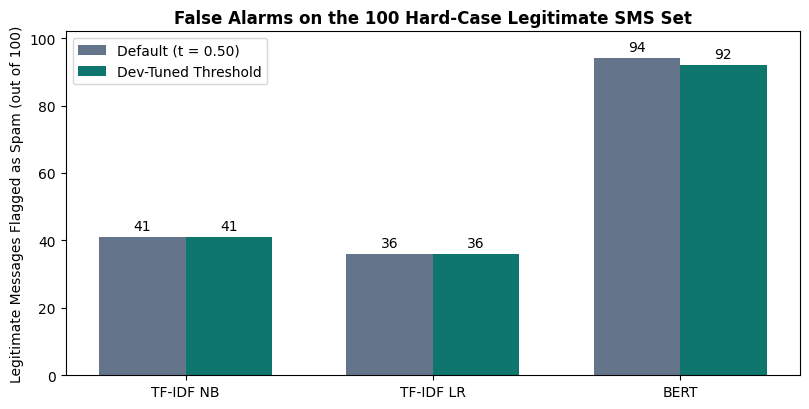

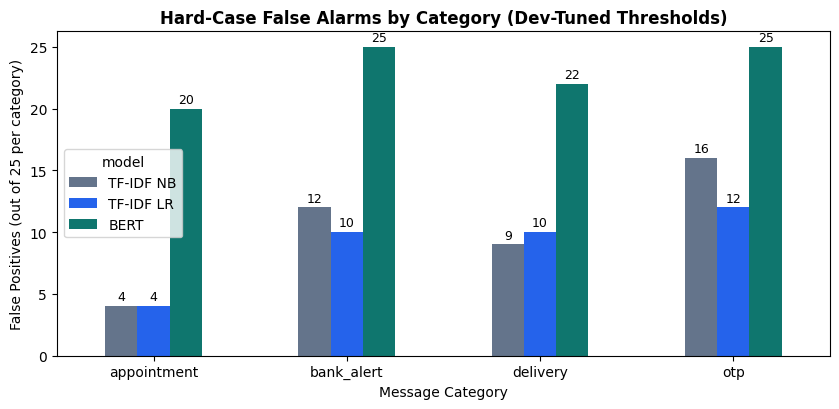

In [8]:
# Extract features/probabilities on the 100 hard cases
X_hard_tfidf = tfidf_vectorizer.transform(hard_df["text"])
hard_probs = {
    "TF-IDF NB": traditional_models["TF-IDF NB"].predict_proba(X_hard_tfidf)[:, 1],
    "TF-IDF LR": traditional_models["TF-IDF LR"].predict_proba(X_hard_tfidf)[:, 1],
    "BERT": bert_predict_proba(bert_model, hard_df["text"], bert_tokenizer),
}

hard_pred_df = hard_df[["id", "category", "text", "label"]].copy()
hard_rows = []

for name in MODEL_ORDER:
    scores = hard_probs[name]
    hard_pred_df[f"{name}_prob"] = scores
    for mode, thresh in [("Default", 0.50), ("Tuned", selected_thresholds[name])]:
        for category in ["All"] + sorted(hard_df["category"].unique()):
            mask = np.ones(len(hard_df), dtype=bool) if category == "All" else hard_df["category"].eq(category).to_numpy()
            n_items = int(mask.sum())
            fp_count = int((scores[mask] >= thresh).sum())
            hard_rows.append({
                "model": name,
                "mode": mode,
                "threshold": thresh,
                "category": category,
                "n": n_items,
                "fp": fp_count,
                "tn": n_items - fp_count,
                "ham_fpr": fp_count / n_items,
            })

hard_metrics_df = pd.DataFrame(hard_rows)
hard_metrics_df.to_csv(RESULTS_DIR / "hard_case_metrics.csv", index=False)
hard_pred_df.to_csv(RESULTS_DIR / "hard_case_predictions.csv", index=False)

print("Hard-Case False Alarms Overall (100 Legitimate Suspicious-Looking Messages):")
display(hard_metrics_df[hard_metrics_df["category"] == "All"].round(4))

print("\nHard-Case False Alarms by Category (at Tuned Thresholds):")
cat_pivot = hard_metrics_df[
    (hard_metrics_df["mode"] == "Tuned") & (hard_metrics_df["category"] != "All")
].pivot(index="category", columns="model", values="fp")[MODEL_ORDER]
display(cat_pivot)

# Bar chart: Default vs Tuned false alarms on the 100 hard cases
overall_hard = hard_metrics_df[hard_metrics_df["category"] == "All"]
xpos = np.arange(len(MODEL_ORDER))
width = 0.35

fig, ax = plt.subplots(figsize=(8.2, 4.2))
default_vals = [int(overall_hard[(overall_hard["model"] == m) & (overall_hard["mode"] == "Default")].iloc[0]["fp"]) for m in MODEL_ORDER]
tuned_vals = [int(overall_hard[(overall_hard["model"] == m) & (overall_hard["mode"] == "Tuned")].iloc[0]["fp"]) for m in MODEL_ORDER]

bars1 = ax.bar(xpos - width / 2, default_vals, width, label="Default (t = 0.50)", color="#64748B")
bars2 = ax.bar(xpos + width / 2, tuned_vals, width, label="Dev-Tuned Threshold", color="#0F766E")
ax.bar_label(bars1, padding=3, fontsize=10)
ax.bar_label(bars2, padding=3, fontsize=10)

ax.set_xticks(xpos)
ax.set_xticklabels(MODEL_ORDER, fontsize=10)
ax.set_ylabel("Legitimate Messages Flagged as Spam (out of 100)")
ax.set_title("False Alarms on the 100 Hard-Case Legitimate SMS Set", fontweight="bold")
ax.set_ylim(0, max(default_vals + tuned_vals) + 8)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "hard_cases_false_alarms.png", dpi=200)
plt.show()

# Category breakdown chart at tuned thresholds
fig, ax = plt.subplots(figsize=(8.5, 4.2))
cat_pivot.plot(kind="bar", ax=ax, color=["#64748B", "#2563EB", "#0F766E"])
ax.set_ylabel("False Positives (out of 25 per category)")
ax.set_xlabel("Message Category")
ax.set_title("Hard-Case False Alarms by Category (Dev-Tuned Thresholds)", fontweight="bold")
ax.tick_params(axis="x", rotation=0)
for container in ax.containers:
    ax.bar_label(container, padding=2, fontsize=9)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "hard_cases_by_category.png", dpi=200)
plt.show()


### 4. Error Analysis & Misleading Vocabulary
To understand *why* mistakes happen:
1. We aggregate positive feature contributions (`tfidf_value * lr_coefficient`) across false positives made by **TF-IDF Logistic Regression** on both the UCI test set and the hard-case set to identify the words most responsible for pushing legitimate messages toward the spam class.
2. We save all misclassified messages from the UCI test set (`results/uci_test_errors.csv`) and hard-case set (`results/hard_case_errors.csv`), and print representative mistakes from each of the three models for inspection and discussion in the report.


Top Misleading Terms in TF-IDF LR False Positives (UCI Test Set):


,term,positive_contribution_sum
0,free,13.1658
1,mobile,2.0579
2,reply,1.5295
3,contact,0.8468
4,service,0.7004
5,com,0.6867
6,www,0.4560
7,customer,0.4489
8,sms,0.4094
9,charge,0.3971


Top Misleading Terms in TF-IDF LR False Positives (Hard-Case Set):


,term,positive_contribution_sum
0,free,7.8154
1,code,6.2062
2,order,3.9131
3,mobile,3.6688
4,account,3.5011
5,delivery,3.3244
6,reply,2.9925
7,service,2.9459
8,text,2.9218
9,new,2.8996


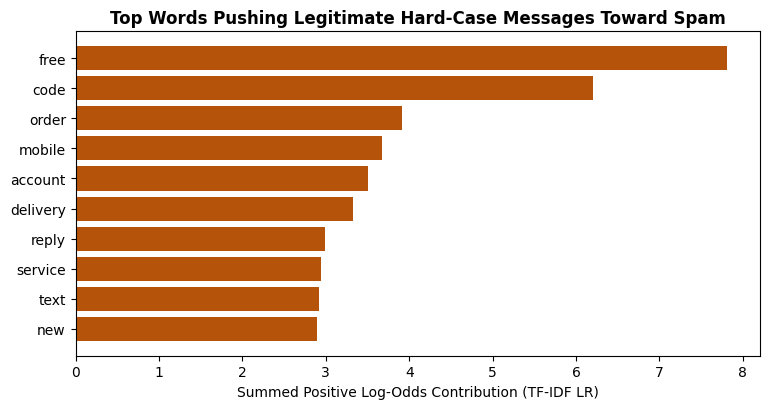


Total UCI test errors across all three models: 43

--- Sample UCI Test Errors for TF-IDF NB (Total: 17) ---


,model,error_type,actual,predicted,spam_prob,threshold,text
0,TF-IDF NB,FN (Spam -> Ham),spam,ham,0.3033,0.5,Call Germany for only 1 pence per minute! Call...
1,TF-IDF NB,FP (Ham -> Spam),ham,spam,0.5823,0.5,We have sent JD for Customer Service cum Accou...
2,TF-IDF NB,FP (Ham -> Spam),ham,spam,0.6726,0.5,There are no other charges after transfer char...
3,TF-IDF NB,FN (Spam -> Ham),spam,ham,0.0529,0.5,Hi if ur lookin 4 saucy daytime fun wiv busty ...



--- Sample UCI Test Errors for TF-IDF LR (Total: 17) ---


,model,error_type,actual,predicted,spam_prob,threshold,text
17,TF-IDF LR,FN (Spam -> Ham),spam,ham,0.3545,0.5,Call Germany for only 1 pence per minute! Call...
18,TF-IDF LR,FP (Ham -> Spam),ham,spam,0.9372,0.5,Are you free now?can i call now?
19,TF-IDF LR,FN (Spam -> Ham),spam,ham,0.3778,0.5,88800 and 89034 are premium phone services cal...
20,TF-IDF LR,FN (Spam -> Ham),spam,ham,0.4617,0.5,"Romantic Paris. 2 nights, 2 flights from £79 B..."



--- Sample UCI Test Errors for BERT (Total: 9) ---


,model,error_type,actual,predicted,spam_prob,threshold,text
34,BERT,FP (Ham -> Spam),ham,spam,0.9994,0.95,MY NO. IN LUTON 0125698789 RING ME IF UR AROUN...
35,BERT,FP (Ham -> Spam),ham,spam,0.9987,0.95,"Hi, Mobile no. &lt;#&gt; has added you in th..."
36,BERT,FN (Spam -> Ham),spam,ham,0.8594,0.95,"New Tones This week include: 1)McFly-All Ab..,..."
37,BERT,FP (Ham -> Spam),ham,spam,0.9981,0.95,Open rebtel with firefox. When it loads just p...



Sample Hard-Case False Alarms by BERT (Total: 92):


,model,id,category,spam_prob,threshold,text
77,BERT,HC001,otp,0.9994,0.95,Your university portal verification code is 48...
78,BERT,HC002,otp,0.9995,0.95,Security alert: use one-time code 739204 to ve...
79,BERT,HC003,otp,0.9994,0.95,Use passcode 194852 to complete your online ba...
80,BERT,HC004,otp,0.9996,0.95,Urgent sign-in check: your 6-digit verificatio...
81,BERT,HC005,otp,0.9995,0.95,Your email account recovery code is 841029. Re...


In [9]:
# 1. Extract top misleading words from TF-IDF Logistic Regression false positives
feature_names = tfidf_vectorizer.get_feature_names_out()
lr_weights = traditional_models["TF-IDF LR"].coef_[0]
pos_weights = np.maximum(lr_weights, 0.0)

def top_misleading_terms(X_mat, fp_mask, top_k=12):
    if not fp_mask.any():
        return pd.DataFrame(columns=["term", "positive_contribution_sum"])
    contrib_sum = np.asarray(X_mat[fp_mask].multiply(pos_weights).sum(axis=0)).ravel()
    top_idx = np.argsort(contrib_sum)[::-1][:top_k]
    return pd.DataFrame({
        "term": feature_names[top_idx],
        "positive_contribution_sum": np.round(contrib_sum[top_idx], 4),
    })

uci_lr_fp = (y_splits["test"] == 0) & (test_probs["TF-IDF LR"] >= selected_thresholds["TF-IDF LR"])
hard_lr_fp = hard_probs["TF-IDF LR"] >= selected_thresholds["TF-IDF LR"]

uci_misleading = top_misleading_terms(X_tfidf["test"], uci_lr_fp, top_k=10)
hard_misleading = top_misleading_terms(X_hard_tfidf, hard_lr_fp, top_k=12)

uci_misleading.to_csv(RESULTS_DIR / "misleading_words_uci.csv", index=False)
hard_misleading.to_csv(RESULTS_DIR / "misleading_words_hard_cases.csv", index=False)

print("Top Misleading Terms in TF-IDF LR False Positives (UCI Test Set):")
display(uci_misleading)

print("Top Misleading Terms in TF-IDF LR False Positives (Hard-Case Set):")
display(hard_misleading)

if len(hard_misleading) > 0:
    fig, ax = plt.subplots(figsize=(7.8, 4.2))
    plot_df = hard_misleading.iloc[:10].iloc[::-1]
    ax.barh(plot_df["term"], plot_df["positive_contribution_sum"], color="#B45309")
    ax.set_xlabel("Summed Positive Log-Odds Contribution (TF-IDF LR)")
    ax.set_title("Top Words Pushing Legitimate Hard-Case Messages Toward Spam", fontweight="bold")
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "misleading_words.png", dpi=200)
    plt.show()

# 2. Collect all UCI test errors and display sample mistakes per model
uci_errors = []
for name in MODEL_ORDER:
    thresh = selected_thresholds[name]
    scores = test_probs[name]
    preds = (scores >= thresh).astype(int)
    for idx in np.flatnonzero(preds != y_splits["test"]):
        uci_errors.append({
            "model": name,
            "error_type": "FP (Ham -> Spam)" if preds[idx] == 1 else "FN (Spam -> Ham)",
            "actual": splits["test"].iloc[idx]["label"],
            "predicted": "spam" if preds[idx] == 1 else "ham",
            "spam_prob": round(float(scores[idx]), 4),
            "threshold": thresh,
            "text": splits["test"].iloc[idx]["text"],
        })

uci_errors_df = pd.DataFrame(uci_errors)
uci_errors_df.to_csv(RESULTS_DIR / "uci_test_errors.csv", index=False)

print(f"\nTotal UCI test errors across all three models: {len(uci_errors_df)}")
for name in MODEL_ORDER:
    subset = uci_errors_df[uci_errors_df["model"] == name]
    print(f"\n--- Sample UCI Test Errors for {name} (Total: {len(subset)}) ---")
    display(subset.head(4))

# 3. Collect hard-case false alarms for inspection
hard_errors = []
for name in MODEL_ORDER:
    thresh = selected_thresholds[name]
    scores = hard_probs[name]
    for idx in np.flatnonzero(scores >= thresh):
        hard_errors.append({
            "model": name,
            "id": hard_df.iloc[idx]["id"],
            "category": hard_df.iloc[idx]["category"],
            "spam_prob": round(float(scores[idx]), 4),
            "threshold": thresh,
            "text": hard_df.iloc[idx]["text"],
        })
hard_errors_df = pd.DataFrame(hard_errors)
hard_errors_df.to_csv(RESULTS_DIR / "hard_case_errors.csv", index=False)
print(f"\nSample Hard-Case False Alarms by BERT (Total: {(hard_errors_df['model']=='BERT').sum()}):")
display(hard_errors_df[hard_errors_df["model"] == "BERT"].head(5))


### 5. Individual Team Examples (Reported Separately from Test Scores)
Each group member authored two original labelled SMS messages (one legitimate `ham` and one `spam`). As required by the course guidelines, these six examples are evaluated independently and never included in training, development, or official test metrics.


In [10]:
# Evaluate the 6 original member-written examples with the selected model
def score_texts_with_model(texts, model_name):
    if model_name == "BERT":
        return bert_predict_proba(bert_model, texts, bert_tokenizer)
    feats = tfidf_vectorizer.transform(texts)
    return traditional_models[model_name].predict_proba(feats)[:, 1]


student_eval = student_df.copy()
for name in MODEL_ORDER:
    probs = score_texts_with_model(student_eval["text"], name)
    thresh = selected_thresholds[name]
    student_eval[f"{name}_pred"] = np.where(probs >= thresh, "spam", "ham")
    student_eval[f"{name}_prob"] = np.round(probs, 4)

student_eval.to_csv(RESULTS_DIR / "student_examples_predictions.csv", index=False)
display(student_eval[["student_name", "label", "text", "TF-IDF NB_pred", "TF-IDF LR_pred", "BERT_pred", "BERT_prob"]])


,student_name,label,text,TF-IDF NB_pred,TF-IDF LR_pred,BERT_pred,BERT_prob
0,Abdulrahman Alshaikh,ham,Your free lab orientation session is confirmed...,ham,ham,spam,0.9932
1,Abdulrahman Alshaikh,spam,"Congratulations! Your mobile number won a 5,00...",spam,spam,spam,0.9994
2,Abdulrahman Fahad AlHumam,ham,Security notice: your university email passwor...,ham,ham,spam,0.9987
3,Abdulrahman Fahad AlHumam,spam,URGENT: Your parcel is held at customs. Click ...,spam,spam,spam,0.9994
4,Ibrahim Khaled Alkhamis,ham,Your free warranty battery replacement is read...,ham,spam,spam,0.9993
5,Ibrahim Khaled Alkhamis,spam,Limited time offer! Triple your income working...,ham,ham,spam,0.9994


## Try it

Use the cell below to classify any unfamiliar SMS message immediately using the already-trained models (**no retraining occurs**). Empty or whitespace-only inputs are handled gracefully with a helpful prompt.


In [11]:
def predict_sms(message: str, model_name: str = None) -> dict:
    """Classify a single SMS message without retraining."""
    if not isinstance(message, str) or not message.strip():
        return {"status": "error", "message": "Input is empty. Please enter a non-empty SMS message."}

    chosen = model_name or SELECTED_DEMO_MODEL
    if chosen not in MODEL_ORDER:
        return {"status": "error", "message": f"Unknown model '{chosen}'. Choose from {MODEL_ORDER}."}

    prob = float(score_texts_with_model([message], chosen)[0])
    thresh = selected_thresholds[chosen]
    label = "Spam" if prob >= thresh else "Not spam"
    return {
        "prediction": label,
        "model": chosen,
        "spam_probability": round(prob, 4),
        "threshold": thresh,
    }


# 1. Interactive single-message check (edit `user_message` to test any new SMS)
user_message = "Your free campus tutoring appointment is confirmed for Monday at 2 pm."
print("Single message test:")
print(predict_sms(user_message))

# 2. Empty-input handling verification
print("\nEmpty input check:")
print(predict_sms("   "))

# 3. Sample unfamiliar inputs summary table
demo_messages = [
    "Your free campus tutoring appointment is confirmed for Monday at 2 pm.",
    "You won a cash prize. Pay a fee now to claim it.",
    "Please bring your notebook to tomorrow's lab.",
    "Security alert: use code 482910 to verify your university portal sign-in.",
]
demo_df = pd.DataFrame([{"text": msg, **predict_sms(msg)} for msg in demo_messages])
demo_df.to_csv(RESULTS_DIR / "demo_predictions.csv", index=False)
display(demo_df)

# Save full run summary for verification against the project report and slides
run_summary = {
    "run_utc": datetime.now(timezone.utc).isoformat(),
    "seed": SEED,
    "device": str(DEVICE),
    "bert_model": BERT_MODEL_NAME,
    "raw_messages": len(raw_df),
    "duplicates_removed": len(raw_df) - len(clean_df),
    "clean_messages": len(clean_df),
    "unique_groups": int(clean_df["group"].nunique()),
    "split_counts": split_table[["ham", "spam", "total"]].to_dict(orient="index"),
    "selected_demo_model": SELECTED_DEMO_MODEL,
    "selected_thresholds": selected_thresholds,
    "uci_test_metrics": test_metrics_df.round(4).to_dict(orient="records"),
    "hard_case_overall": hard_metrics_df[hard_metrics_df["category"] == "All"].round(4).to_dict(orient="records"),
}
(RESULTS_DIR / "run_summary.json").write_text(json.dumps(run_summary, indent=2), encoding="utf-8")
print("\nAll outputs and run_summary.json saved to results/.")


Single message test:
{'prediction': 'Spam', 'model': 'BERT', 'spam_probability': 0.9831, 'threshold': 0.95}

Empty input check:
{'status': 'error', 'message': 'Input is empty. Please enter a non-empty SMS message.'}


,text,prediction,model,spam_probability,threshold
0,Your free campus tutoring appointment is confi...,Spam,BERT,0.9831,0.95
1,You won a cash prize. Pay a fee now to claim it.,Not spam,BERT,0.0066,0.95
2,Please bring your notebook to tomorrow's lab.,Not spam,BERT,0.0015,0.95
3,Security alert: use code 482910 to verify your...,Spam,BERT,0.9994,0.95



All outputs and run_summary.json saved to results/.


## Sources

1. **UCI SMS Spam Collection Dataset:** T. A. Almeida, J. M. G. Hidalgo, and A. Yamakami (2011), *Contributions to the Study of SMS Spam Filtering: New Collection and Results*, ACM Symposium on Document Engineering (DocEng '11). Available at: https://doi.org/10.24432/C5CC84
2. **BERT Pretrained Language Model:** J. Devlin, M.-W. Chang, K. Lee, and K. Toutanova (2019), *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding*, Proceedings of NAACL-HLT 2019, pp. 4171–4186. Available at: https://aclanthology.org/N19-1423/
3. **Hugging Face Transformers (BERT Documentation & Weights):** `bert-base-uncased` model and PyTorch classification documentation. Available at: https://huggingface.co/docs/transformers/model_doc/bert
4. **Scikit-learn Classification Threshold Tuning:** Official documentation on separating probability estimation from decision threshold selection. Available at: https://scikit-learn.org/stable/modules/classification_threshold.html
